# 01 — Datos, procedencia y partición temporal

El estudio compara modelos que predicen masa, utilización promedio y desplazamiento, y examina qué diseños históricos permiten priorizar. La unidad de regresión es el diseño definido por sus siete entradas exactas; las apariciones poblacionales pertenecen a una sola trayectoria evolutiva.

Esta presentación lee el manifiesto y las tablas del cierre seleccionado. Las cifras siguientes corresponden a esa campaña; no se reconstruye el dataset ni se ajustan modelos. [CONTEXT.md](../CONTEXT.md) describe las preguntas de investigación y [data/README.md](../data/README.md) documenta la procedencia.

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = {"png", "svg"}
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from truss_research.evaluacion.presentacion import notebook_context

context = notebook_context()
CONFIG = context.config
STUDY_DIR, REPORT_DIR = context.study_dir, context.report_dir
DATA_DIR = CONFIG.data_dir
display(
    Markdown(
        f"**Estudio:** `{STUDY_DIR.name}` — **etiqueta:** `{CONFIG.label}` — **informe:** `{REPORT_DIR.name}`"
    )
)
if CONFIG.label == "comprobacion":
    display(
        Markdown(
            "**Comprobación técnica: sus métricas no constituyen resultados de tesis.**"
        )
    )

**Estudio:** `comparacion_tres_objetivos_final_002` — **etiqueta:** `posterior` — **informe:** `informe_001`

## 1. Entradas y respuestas

`web_config` es nominal. Los identificadores y las respuestas no son entradas del predictor. Masa se expresa en kg, desplazamiento Z en m y utilización promedio como ratio. El significado físico procede de las declaraciones registradas; no se deduce solo del Excel.

In [2]:
from truss_research.cerchas.schemas import INPUT_COLUMNS, OUTPUT_COLUMNS
from truss_research.datos.procesados import read_manifest

manifest = read_manifest(DATA_DIR)
training = pd.read_csv(DATA_DIR / "train.csv", float_precision="round_trip")
full = pd.read_csv(DATA_DIR / "full_clean.csv", float_precision="round_trip")
display(
    pd.DataFrame(
        {
            "variable": [*INPUT_COLUMNS, *OUTPUT_COLUMNS],
            "rol": ["entrada"] * len(INPUT_COLUMNS)
            + ["respuesta"] * len(OUTPUT_COLUMNS),
        }
    )
)
display(training[["iter_id", *INPUT_COLUMNS, *OUTPUT_COLUMNS]].head())

,variable,rol
0,web_config,entrada
1,n_trusses,entrada
2,lr_height_m,entrada
3,lmrm_height_m,entrada
4,m_height_m,entrada
5,subdiv1,entrada
6,subdiv2,entrada
7,mass_kg,respuesta
8,util_ratio,respuesta
9,z_disp_m,respuesta


,iter_id,web_config,n_trusses,lr_height_m,lmrm_height_m,m_height_m,subdiv1,subdiv2,mass_kg,util_ratio,z_disp_m
0,{0;0},1,8,1.7,2.7,2.4,5,4,5971.843110,0.607654,0.039550
1,{0;1},4,8,2.3,0.3,1.0,4,10,12214.234639,0.563404,0.137789
2,{0;2},3,34,1.1,2.2,2.5,7,10,19857.214639,0.356578,0.027619
3,{0;3},0,11,1.5,2.8,0.8,8,4,10404.955193,0.460121,0.073851
4,{0;4},3,45,2.0,2.6,2.5,1,10,27341.848910,0.361055,0.020184


## 2. Apariciones, identidad y duplicados

La identidad usa igualdad exacta de las siete entradas, sin redondear alturas. La preparación comprueba respuestas coincidentes antes de conservar el representante de menor generación y solución. La frecuencia no pondera el entrenamiento.

Cada generación registra una población; el índice de solución no establece orden de evaluación. Cruce, mutación y elitismo requieren evidencia del algoritmo original. Una reaparición no prueba otra llamada FEM.

In [3]:
display(pd.Series(manifest["design_audit"], name="Auditoría del origen"))
membership = pd.read_csv(DATA_DIR / "design_membership.csv")
display(membership[["iter_id", "representative_iter_id", "split"]].head(8))

rows                                                                         5000
unique_designs                                                               1273
repeated_rows                                                                3727
conflicting_designs                                                             0
max_response_ranges             {'mass_kg': 0.0, 'util_ratio': 0.0, 'z_disp_m'...
unique_designs_by_web_config      {'0': 12, '1': 538, '2': 666, '3': 46, '4': 11}
generation_component_sizes                                                  [100]
Name: Auditoría del origen, dtype: object

,iter_id,representative_iter_id,split
0,{0;0},{0;0},train
1,{0;1},{0;1},train
2,{0;2},{0;2},train
3,{0;3},{0;3},train
4,{0;4},{0;4},train
5,{0;5},{0;5},train
6,{0;6},{0;6},train
7,{0;7},{0;7},train


## 3. Primera aparición y cobertura temporal

Los diseños se separan por la generación en que aparecen por primera vez: ajuste, calibración, validación y prueba. Un superviviente conserva su conjunto original, evitando que la repetición exacta de una geometría aparezca a ambos lados de la evaluación. Las categorías no se trasladan para equilibrar artificialmente los bloques.

La cobertura temporal se describe junto con la cobertura de topologías. Las categorías ausentes de un bloque no tienen una evaluación en él; nuevas semillas de entrenamiento no compensan esa ausencia. La partición reduce la mezcla temporal, pero no convierte una sola trayectoria previamente examinada en problemas independientes ni en una prueba inédita.

,conjunto,diseños,primera_generación_mínima,primera_generación_máxima
0,full,1273,0,99
1,train,901,0,63
2,validation,98,80,89
3,test,108,90,99
4,calibration,166,64,79


train_to_validation_shared_designs          0
train_to_test_shared_designs                0
train_to_calibration_shared_designs         0
validation_to_test_shared_designs           0
validation_to_calibration_shared_designs    0
test_to_calibration_shared_designs          0
Name: Diseños compartidos, dtype: int64

,web_config,unique_designs,split,scarce_evidence,scarcity_threshold,interpretation
0,0,10,train,False,10,descriptive_threshold_not_statistical_power
1,1,393,train,False,10,descriptive_threshold_not_statistical_power
2,2,441,train,False,10,descriptive_threshold_not_statistical_power
3,3,46,train,False,10,descriptive_threshold_not_statistical_power
4,4,11,train,False,10,descriptive_threshold_not_statistical_power
5,0,2,validation,True,10,descriptive_threshold_not_statistical_power
6,1,39,validation,False,10,descriptive_threshold_not_statistical_power
7,2,57,validation,False,10,descriptive_threshold_not_statistical_power
8,3,0,validation,True,10,descriptive_threshold_not_statistical_power
9,4,0,validation,True,10,descriptive_threshold_not_statistical_power


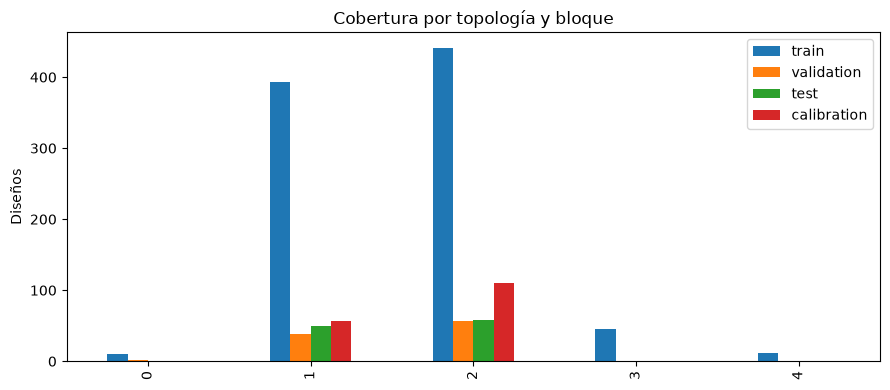

**Muestra del cierre:** 1273 diseños únicos; 901 de ajuste, 166 de calibración, 98 de validación y 108 de prueba. La ausencia de diseños compartidos y la cobertura por topología deben leerse conjuntamente.

In [4]:
diagnostics = manifest["diagnostics"]
partitions = pd.DataFrame(
    [
        {
            "conjunto": name,
            "diseños": row["rows"],
            "primera_generación_mínima": min(row["generations"]),
            "primera_generación_máxima": max(row["generations"]),
        }
        for name, row in diagnostics.items()
    ]
)
display(partitions)
display(pd.Series(manifest["design_overlap"], name="Diseños compartidos"))
coverage = pd.read_csv(REPORT_DIR / "category_coverage.csv")
display(coverage)
counts = pd.DataFrame(
    {
        name: row["web_config_counts"]
        for name, row in diagnostics.items()
        if name != "full"
    }
).fillna(0)
counts.plot.bar(
    figsize=(9, 4), ylabel="Diseños", title="Cobertura por topología y bloque"
)
plt.tight_layout()
plt.show()

display(
    Markdown(
        f"**Muestra del cierre:** {len(full)} diseños únicos; "
        f"{diagnostics['train']['rows']} de ajuste, "
        f"{diagnostics['calibration']['rows']} de calibración, "
        f"{diagnostics['validation']['rows']} de validación y "
        f"{diagnostics['test']['rows']} de prueba. "
        "La ausencia de diseños compartidos y la cobertura por topología deben leerse conjuntamente."
    )
)

## 4. Umbrales y distribución de entrenamiento

L/700 es un criterio operativo adoptado, no una restricción demostrada del generador original. Se conservan los diseños que incumplen umbrales. La utilización promedio no certifica cada barra; la ausencia de ratios mayores que uno no demuestra un filtrado previo del optimizador.

Los conteos globales describen el archivo ya examinado. Las decisiones de ajuste se apoyan en entrenamiento; los histogramas siguientes usan únicamente ese bloque.

diseños_únicos                  1273.000000
límite_Z_m                         0.028571
cumplen_Z                        835.000000
exceden_Z                        438.000000
utilización_máxima_observada       0.912926
exceden_utilización                0.000000
dtype: float64

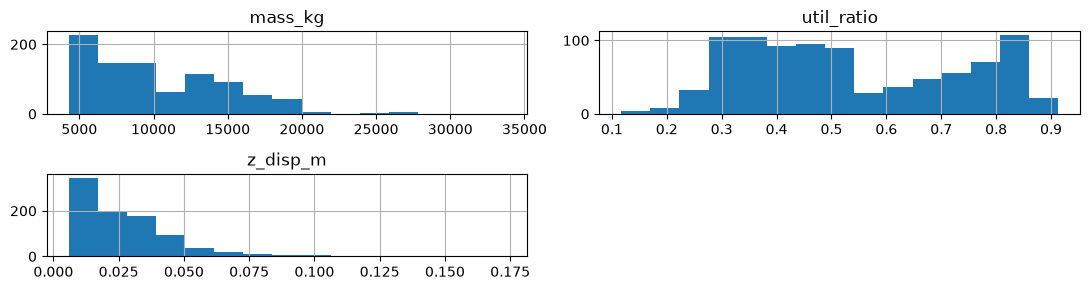

In [5]:
limits = manifest["limits"]
z_limit = limits["displacement_limit_m"]
z_compliance = (
    full["z_disp_m"].le(z_limit)
    if z_limit is not None
    else pd.Series(True, index=full.index)
)
display(
    pd.Series(
        {
            "diseños_únicos": len(full),
            "límite_Z_m": z_limit,
            "cumplen_Z": int(z_compliance.sum()),
            "exceden_Z": int((~z_compliance).sum()),
            "utilización_máxima_observada": full["util_ratio"].max(),
            "exceden_utilización": int(
                full["util_ratio"].gt(limits["utilization_limit"]).sum()
            ),
        }
    )
)
training[list(OUTPUT_COLUMNS)].hist(figsize=(11, 3), bins=15)
plt.tight_layout()
plt.show()

## 5. Procedencia, alcance y lectura del caso

Los datos permiten comparar predictores y estrategias dentro del archivo disponible. No bastan para reconstruir el evaluador estructural original ni certificar nuevas configuraciones: la ficha siguiente distingue declaraciones registradas de información pendiente.

El documento histórico `docs/SCOPE.md` citado en la procedencia no está disponible. Cargas, apoyos, asignaciones de secciones, solver y agregación exacta de respuestas requieren evidencia de la fuente. La interpretación de los resultados conserva esa limitación y el conocimiento previo del conjunto de prueba.

In [6]:
display(pd.read_csv(REPORT_DIR / "physical_provenance.csv"))
display(Markdown((REPORT_DIR / "EVIDENCE.md").read_text(encoding="utf-8")))

,element,status,evidence,confirmation_required,confirmation_source,confirmed_at
0,Archivo y hoja,Confirmado,"240214-C1-20m.xlsx, TOTAL DATA; manifiesto rep...",Conservar identidad de la fuente.,Registro histórico de respuesta de la profesor...,2026-10-19
1,SHA-256,Confirmado,f05c11f9a980497dcf5b74f3b74547244ce020552f95dc...,Verificar al preparar.,Registro histórico de respuesta de la profesor...,2026-10-19
2,Acceso y autorización,Informado por el autor,Fuente autorizada de acceso restringido; LICENSE.,Conservar evidencia de autorización sin public...,NaN,NaN
3,"Cerchas de acero 2D, luz 20 m",Confirmado,Luz fija de 20 m; alturas y secciones variables.,No interpretar luz fija como sección fija.,Registro histórico de respuesta de la profesor...,2026-10-19
4,Origen en optimización topológica,Informado por el autor,Optimización de alternativas geométricas y sel...,"Precisar algoritmo, software, versiones y pará...",NaN,NaN
5,Análisis estructural FEM,Confirmado,La profesora confirma análisis mediante elemen...,"Precisar solver, software y versión; FEM no id...",Registro histórico de respuesta de la profesor...,2026-10-19
6,Cargas y apoyos,Pendiente,No constan en el Excel ni en la respuesta.,"Cargas, combinaciones, apoyos, separación y ví...",NaN,NaN
7,Materiales y secciones,Confirmado,Acero A36 con fluencia 250 MPa; comprobaciones...,250 MPa no es una tensión admisible universal.,Registro histórico de respuesta de la profesor...,2026-10-21
8,Asignación y propiedades por barra,Pendiente,El optimizador seleccionaba secciones por barr...,"Catálogo completo, perfiles por barra, conecti...",NaN,NaN
9,Generaciones y soluciones,Confirmado,"100 generaciones sucesivas (0 a 99), con 50 ap...",No interpretar la solución 0 como diseño base ...,Registro histórico de respuesta de la profesor...,2026-10-19


# Alcance de la evidencia

MAE normalizado divide por desviaciones de entrenamiento; no es porcentaje de error relativo. El remuestreo predictivo usa diseños pareados después de promediar pérdidas entre semillas.

La búsqueda es una aplicación exploratoria secundaria. Sus intervalos remuestrean semillas de aprendizaje y escenarios emparejados; no son nuevos problemas estructurales independientes. El acuerdo entre evaluador y auditor no verifica diseños nuevos.

Se midieron duración, CPU y RSS máxima muestreada. RSS incluye bibliotecas y puede perder picos breves; no es memoria exclusiva del modelo ni un máximo físico continuo. El tiempo acumulado de trabajos difiere del tiempo transcurrido de campaña.

La latencia individual se conserva. Los ceros de CPU cruda pueden estar bajo resolución; la pasada CPU agrupada declara llamadas, granularidad y alcance. CPU de episodio simulado no es CPU exclusiva de decisiones ni costo de un solver.

La prueba ya observada conserva carácter exploratorio. Se comparan diseños registrados de una fuente y partición fija; no se acredita extrapolación a problemas nuevos, generación de topologías, seguridad por barra ni aceleración del solver original.

La estabilidad describe ajustes finales con partición e hiperparámetros fijos. Predicciones idénticas entre semillas indican determinismo condicionado, no réplicas independientes ni certeza poblacional.

Los errores extremos se conservan. Las métricas sin el peor caso son únicamente un diagnóstico de influencia y no sustituyen las métricas principales ni justifican excluir diseños.

Grupos con menos de 10 diseños únicos se señalan como evidencia escasa, sin garantizar suficiencia para grupos mayores. Las confirmaciones físicas requieren fuente y fecha; no se infieren del entrenamiento.
